In [4]:
%pip install -q torch torchvision segmentation-models-pytorch numpy scipy scikit-learn matplotlib
%pip install -q rasterio geopandas shapely pyproj pyogrio networkx requests folium pystac-client planetary-computer

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import os, io, json, math, glob, tarfile, random, time as time_mod, warnings
from pathlib import Path
from datetime import date, timedelta
import numpy as np
import scipy.ndimage as ndi
import torch, torch.nn as nn, torch.nn.functional as F
import rasterio, rasterio.features
from rasterio.crs import CRS
from rasterio.enums import Resampling
from rasterio.transform import from_origin, array_bounds
from rasterio.vrt import WarpedVRT
from rasterio.warp import calculate_default_transform, reproject
from pyproj import Transformer
warnings.filterwarnings("ignore")

# ---------------- paths ----------------
BASE_DIR  = Path(r"C:\NIT KKR\after placement\iit mandi hackathon\dataset")
TRAIN_DIR = BASE_DIR / "train_grd"
VAL_DIR   = BASE_DIR / "val_grd"        # optional; if missing, 10% of train shards are held out
TEST_DIR  = BASE_DIR / "test_grd"
OUT_DIR   = BASE_DIR.parent / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- Kuro Siwo tar layout (verify in Cell 3) ----------------
CHANNEL_KEYS = ["sec1_vv", "sec1_vh", "sec2_vv", "sec2_vh", "flood_vv", "flood_vh", "dem"]
MASK_KEY, VALID_KEY = "mask", "valid_mask"   # labels: 0 no water, 1 permanent water, 2 flood

# ---------------- training ----------------
SEED, EPOCHS, BATCH, LR = 42, 15, 16, 3e-4
STATS_SAMPLES, CLIP, SHUFFLE_BUF = 1500, 5.0, 512
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---------------- case study ----------------
EVENT_DATE = "2026-08-26"
AOI_BBOX = (85.15, 27.93, 85.45, 28.25)      # lon_min, lat_min, lon_max, lat_max (Syabrubesi -> Betrawati). Edit as needed.
GRID_RES = 10
PRE_WINDOW_DAYS, POST_WINDOW_DAYS, POST_MIN_OFFSET_DAYS = 60, 20, 1
# post-processing rules (fixed a priori, NOT tuned on EMSR927)
PRE_DARK_DB, SLOPE_MAX_DEG, MIN_AREA_PX = -18.0, 20.0, 15
BASELINE_DROP_DB, BASELINE_POST_DB = -3.0, -15.0
# OSM / analysis
OSM_TIME = "2026-08-25"                       # pre-event snapshot only
SCENARIOS = {"inside_flood": 0, "buffer_25m": 25}   # road-disable distance in metres
PRIMARY_SCENARIO = "inside_flood"
SNAP_MAX_M = 500
RESPONSE_POINTS = []                          # [(name, lon, lat), ...] extra rescue/response locations

ATTR = {
    "sentinel": "Contains modified Copernicus Sentinel data 2026.",
    "dem": "Produced using Copernicus WorldDEM-30 © DLR e.V. 2010–2014 and © Airbus Defence and Space GmbH 2014–2018 provided under COPERNICUS by the European Union and ESA; all rights reserved.",
    "osm": "© OpenStreetMap contributors.",
    "kuro": "Kuro Siwo: Bountos et al., 2024 (Kuro Siwo repository).",
}
DISCLAIMER = ("Educational prototype, not an operational emergency-response system. Sentinel revisit gaps, AI false "
              "positives/negatives, possible poor transfer from Kuro Siwo to Himalayan terrain, incomplete OSM, and "
              "connectivity estimates that do not guarantee physical passability all apply.")

# ---------------- json / results ----------------
def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
def load_json(path):
    with open(path) as f: return json.load(f)
RES_PATH = OUT_DIR / "results.json"
R = load_json(RES_PATH) if RES_PATH.exists() else {}
def save_results(): save_json(R, RES_PATH)

# ---------------- tar shard reader (no webdataset, Windows-safe) ----------------
def iter_shard(path):
    with tarfile.open(str(path)) as tf:
        cur_key, cur = None, {}
        for m in tf:
            if not m.isfile(): continue
            name = os.path.basename(m.name)
            if "." not in name: continue
            stem, ext = name.split(".", 1)
            if not ext.endswith(".npy"): continue
            if stem != cur_key:
                if cur: yield cur_key, cur
                cur_key, cur = stem, {}
            cur[ext[:-4]] = np.load(io.BytesIO(tf.extractfile(m).read()), allow_pickle=False)
        if cur: yield cur_key, cur

class TarShardDataset(torch.utils.data.IterableDataset):
    def __init__(self, shards, transform, shuffle=False, buffer=SHUFFLE_BUF, seed=0, limit=None):
        self.shards = [str(s) for s in shards]; self.transform = transform
        self.shuffle, self.buffer, self.seed, self.limit, self.epoch = shuffle, buffer, seed, limit, 0
    def __iter__(self):
        rng = random.Random(self.seed + self.epoch); self.epoch += 1
        shards = list(self.shards)
        if self.shuffle: rng.shuffle(shards)
        buf, n = [], 0
        for sh in shards:
            for _, sample in iter_shard(sh):
                item = self.transform(sample)
                if self.shuffle:
                    buf.append(item)
                    if len(buf) >= self.buffer:
                        j = rng.randrange(len(buf)); buf[j], buf[-1] = buf[-1], buf[j]
                        yield buf.pop(); n += 1
                else:
                    yield item; n += 1
                if self.limit and n >= self.limit: return
        rng.shuffle(buf)
        for it in buf:
            if self.limit and n >= self.limit: return
            yield it; n += 1

# ---------------- preprocessing (shared by training and Himalayan inference) ----------------
def sample_to_raw(sample):
    missing = [k for k in CHANNEL_KEYS + [MASK_KEY] if k not in sample]
    if missing: raise KeyError(f"Missing keys {missing}; available: {list(sample.keys())}")
    chans = [np.squeeze(sample[k]).astype(np.float32) for k in CHANNEL_KEYS]
    raw = np.stack(chans, 0)
    mask = np.squeeze(sample[MASK_KEY]).astype(np.int16)
    valid = np.squeeze(sample[VALID_KEY]).astype(bool) if VALID_KEY in sample else ((mask >= 0) & (mask <= 2))
    return raw, mask, valid

def detect_sar_mode(vals):
    v = vals[np.isfinite(vals)]
    med = float(np.median(v))
    if np.percentile(v, 1) >= 0 and med < 10: return "linear", med
    if med < -5: return "db", med
    if med < 0: return "log10", med
    raise ValueError(f"Cannot infer SAR scale (median={med})")

def raw_to_domain(raw, mode):
    x = raw.copy()
    if mode == "linear":
        s = x[:6]
        x[:6] = np.where(s > 0, 10 * np.log10(np.where(s > 0, s, 1)), np.nan)
    return x

def lin_to_domain(lin, mode):            # for Himalayan linear-power rasters
    out = np.full(lin.shape, np.nan, np.float32); ok = lin > 0
    out[ok] = np.log10(lin[ok]) if mode == "log10" else 10 * np.log10(lin[ok])
    return out

def normalize(x, stats):
    m = np.array(stats["mean"], np.float32)[:, None, None]
    s = np.array(stats["std"], np.float32)[:, None, None]
    z = (x - m) / (s + 1e-6)
    z = np.nan_to_num(z, nan=0.0, posinf=0.0, neginf=0.0)
    return np.clip(z, -CLIP, CLIP).astype(np.float32)

def make_transform(stats):
    mode = stats["sar_mode"]
    def tf(sample):
        raw, mask, valid = sample_to_raw(sample)
        x = raw_to_domain(raw, mode)
        valid = valid & np.isfinite(x).all(0)
        z = normalize(x, stats)
        y = (mask == 2).astype(np.float32)
        return (torch.from_numpy(z), torch.from_numpy(y[None]), torch.from_numpy(valid.astype(np.float32)[None]))
    return tf

# ---------------- model / loss / metrics ----------------
def build_model(pretrained=True):
    import segmentation_models_pytorch as smp
    try:
        m = smp.Unet("resnet18", encoder_weights="imagenet" if pretrained else None, in_channels=7, classes=1)
    except Exception as e:
        print("Pretrained weights unavailable, using random init:", e)
        m = smp.Unet("resnet18", encoder_weights=None, in_channels=7, classes=1)
    return m.to(DEVICE)

def masked_loss(logits, y, v):
    bce = F.binary_cross_entropy_with_logits(logits, y, reduction="none")
    bce = (bce * v).sum() / v.sum().clamp(min=1)
    p = torch.sigmoid(logits) * v
    inter = (p * y).sum(); den = p.sum() + (y * v).sum()
    return bce + (1 - (2 * inter + 1) / (den + 1))

THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.05), 2)
def counts_to_metrics(tp, fp, fn):
    e = 1e-9
    return dict(iou=tp/(tp+fp+fn+e), f1=2*tp/(2*tp+fp+fn+e), precision=tp/(tp+fp+e), recall=tp/(tp+fn+e),
                tp=int(tp), fp=int(fp), fn=int(fn))

@torch.no_grad()
def evaluate(model, loader, thresholds=THRESHOLDS):
    model.eval()
    th = torch.tensor(thresholds, device=DEVICE, dtype=torch.float32).view(-1, 1)
    T = len(thresholds)
    tp = torch.zeros(T, dtype=torch.float64, device=DEVICE); fp = torch.zeros_like(tp); fn = torch.zeros_like(tp)
    for x, y, v in loader:
        x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        p = torch.sigmoid(model(x)); m = v > 0.5
        pv = p[m].view(1, -1); yv = (y[m] > 0.5).view(1, -1)
        pred = pv >= th
        tp += (pred & yv).sum(1).double(); fp += (pred & ~yv).sum(1).double(); fn += ((~pred) & yv).sum(1).double()
    return [dict(threshold=float(t), **counts_to_metrics(float(a), float(b), float(c)))
            for t, a, b, c in zip(thresholds, tp.cpu(), fp.cpu(), fn.cpu())]

# ---------------- geo helpers ----------------
def make_grid(bbox, res):
    lon0, lat0, lon1, lat1 = bbox
    epsg = 32600 + int(((lon0 + lon1) / 2 + 180) // 6) + 1
    tr = Transformer.from_crs(4326, epsg, always_xy=True)
    xs, ys = tr.transform([lon0, lon1, lon0, lon1], [lat0, lat0, lat1, lat1])
    xmin, xmax = math.floor(min(xs)/res)*res, math.ceil(max(xs)/res)*res
    ymin, ymax = math.floor(min(ys)/res)*res, math.ceil(max(ys)/res)*res
    return dict(epsg=epsg, crs=CRS.from_epsg(epsg), transform=from_origin(xmin, ymax, res, res),
                width=int((xmax-xmin)/res), height=int((ymax-ymin)/res), bounds=(xmin, ymin, xmax, ymax), res=res)

def read_to_grid(href, grid, resampling=Resampling.bilinear):
    env = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.tiff",
               GDAL_HTTP_MAX_RETRY="5", GDAL_HTTP_RETRY_DELAY="2")
    with rasterio.Env(**env):
        with rasterio.open(href) as src:
            with WarpedVRT(src, crs=grid["crs"], transform=grid["transform"], width=grid["width"],
                           height=grid["height"], resampling=resampling, src_nodata=src.nodata,
                           nodata=np.nan, dtype="float32") as vrt:
                return vrt.read(1)

def save_geotiff(path, arr, grid, nodata=None, dtype=None):
    a = arr if arr.ndim == 3 else arr[None]
    with rasterio.open(path, "w", driver="GTiff", height=a.shape[1], width=a.shape[2], count=a.shape[0],
                       dtype=dtype or a.dtype, crs=grid["crs"], transform=grid["transform"],
                       nodata=nodata, compress="deflate") as dst:
        dst.write(a.astype(dtype or a.dtype))

def read_tif(path):
    with rasterio.open(path) as ds:
        arr = ds.read()
        grid = dict(epsg=ds.crs.to_epsg(), crs=ds.crs, transform=ds.transform, width=ds.width, height=ds.height,
                    bounds=tuple(ds.bounds), res=ds.res[0])
    return arr, grid

def to_wgs84(arr, grid, resampling=Resampling.bilinear):
    dst_t, w, h = calculate_default_transform(grid["crs"], "EPSG:4326", grid["width"], grid["height"], *grid["bounds"])
    out = np.full((h, w), np.nan, np.float32)
    reproject(arr.astype(np.float32), out, src_transform=grid["transform"], src_crs=grid["crs"],
              dst_transform=dst_t, dst_crs="EPSG:4326", resampling=resampling, src_nodata=np.nan, dst_nodata=np.nan)
    return out, array_bounds(h, w, dst_t)    # (west, south, east, north)

print("Device:", DEVICE, "| outputs ->", OUT_DIR)

Device: cuda | outputs -> C:\NIT KKR\after placement\iit mandi hackathon\outputs


In [5]:
train_shards = sorted(TRAIN_DIR.glob("*.tar"))
if not train_shards: raise FileNotFoundError(f"No .tar in {TRAIN_DIR}")
print(len(train_shards), "train shards")

key0, s0 = next(iter_shard(train_shards[0]))
print("Sample id:", key0)
for k, v in s0.items():
    print(f"  {k:14s} shape={v.shape} dtype={v.dtype} min={np.nanmin(v):.4g} max={np.nanmax(v):.4g}")

# detect SAR scale from real data
vals = []
for i, (_, s) in enumerate(iter_shard(train_shards[0])):
    if i >= 64: break
    raw, mask, valid = sample_to_raw(s)
    vals.append(raw[:6, valid][:, ::97].ravel())
SAR_MODE, med = detect_sar_mode(np.concatenate(vals))
print(f"SAR scale detected: {SAR_MODE} (median raw value {med:.3f})")
print("Mask labels in first sample:", np.unique(np.squeeze(s0[MASK_KEY])))

# per-channel mean/std over valid pixels in the model's input domain
n = np.zeros(7); sm = np.zeros(7); sq = np.zeros(7); pos = 0; tot = 0; cnt = 0
for sh in train_shards:
    for _, s in iter_shard(sh):
        raw, mask, valid = sample_to_raw(s)
        x = raw_to_domain(raw, SAR_MODE)
        v = valid & np.isfinite(x).all(0)
        xv = x[:, v].astype(np.float64)
        n += xv.shape[1]; sm += xv.sum(1); sq += (xv ** 2).sum(1)
        pos += int(((mask == 2) & v).sum()); tot += int(v.sum()); cnt += 1
        if cnt >= STATS_SAMPLES: break
    if cnt >= STATS_SAMPLES: break
mean = sm / n; std = np.sqrt(np.maximum(sq / n - mean ** 2, 1e-12))
STATS = dict(sar_mode=SAR_MODE, mean=mean.tolist(), std=std.tolist(), channel_keys=CHANNEL_KEYS,
             clip=CLIP, flood_fraction=pos / max(tot, 1), samples_used=cnt)
save_json(STATS, OUT_DIR / "norm_stats.json")
print("mean:", np.round(mean, 3)); print("std :", np.round(std, 3))
print(f"Flood pixel fraction: {pos / max(tot, 1):.4%}  (very low means class imbalance, hence the Dice loss)")

5 train shards
Sample id: 000000
  flood_vv       shape=(1, 224, 224) dtype=float32 min=0.003217 max=1.032
  flood_vh       shape=(1, 224, 224) dtype=float32 min=0.001893 max=12.24
  sec1_vv        shape=(1, 224, 224) dtype=float32 min=0.01484 max=0.9057
  sec1_vh        shape=(1, 224, 224) dtype=float32 min=0.001854 max=1.982
  sec2_vv        shape=(1, 224, 224) dtype=float32 min=0.01018 max=0.7871
  sec2_vh        shape=(1, 224, 224) dtype=float32 min=0.002129 max=1.42
  dem            shape=(1, 224, 224) dtype=float32 min=104.1 max=137.9
  mask           shape=(1, 224, 224) dtype=float32 min=0 max=2
  valid_mask     shape=(1, 224, 224) dtype=float32 min=1 max=1
SAR scale detected: linear (median raw value 0.025)
Mask labels in first sample: [0. 2.]
mean: [-10.203 -17.237 -10.583 -17.652  -9.809 -16.376  35.096]
std : [  3.947   3.885   4.129   4.111   4.44    4.22  990.238]
Flood pixel fraction: 7.2538%  (very low means class imbalance, hence the Dice loss)


train shards: 4 | val shards: 1
  ep1 batch50 loss 0.9666
  ep1 batch100 loss 0.4807
  ep1 batch150 loss 0.4174
  ep1 batch200 loss 0.2702
  ep1 batch250 loss 0.3301
  ep1 batch300 loss 0.3568
  ep1 batch350 loss 0.2780
  ep1 batch400 loss 0.2267
  ep1 batch450 loss 0.4027
  ep1 batch500 loss 0.6721
  ep1 batch550 loss 0.6263
  ep1 batch600 loss 0.3640
  ep1 batch650 loss 0.3234
  ep1 batch700 loss 0.7235
  ep1 batch750 loss 0.2424
  ep1 batch800 loss 0.2952
  ep1 batch850 loss 0.2607
  ep1 batch900 loss 0.3131
  ep1 batch950 loss 0.4610
  ep1 batch1000 loss 0.4552
  ep1 batch1050 loss 0.1983
  ep1 batch1100 loss 0.3492
  ep1 batch1150 loss 0.3518
  ep1 batch1200 loss 0.3188
Epoch 1/15 loss 0.4151 | val IoU 0.6333 @thr 0.3 | 612s
  ep2 batch50 loss 0.6834
  ep2 batch100 loss 0.5539
  ep2 batch150 loss 0.2904
  ep2 batch200 loss 0.3500
  ep2 batch250 loss 0.6078
  ep2 batch300 loss 0.2919
  ep2 batch350 loss 0.2533
  ep2 batch400 loss 0.2477
  ep2 batch450 loss 0.0917
  ep2 batch500 los

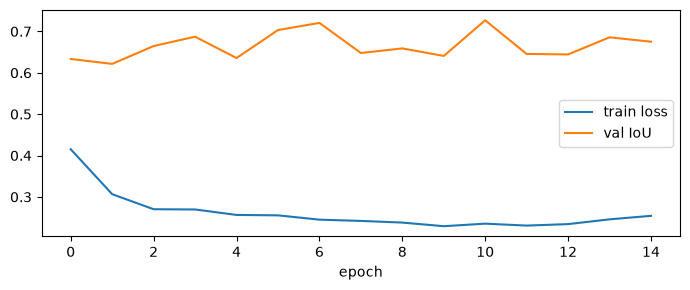

In [6]:
import matplotlib.pyplot as plt
STATS = load_json(OUT_DIR / "norm_stats.json"); TF = make_transform(STATS)

all_shards = sorted(TRAIN_DIR.glob("*.tar"))
val_shards = sorted(VAL_DIR.glob("*.tar")) if VAL_DIR.exists() else []
if val_shards:
    train_shards = all_shards
else:
    sh = all_shards[:]; random.Random(SEED).shuffle(sh)
    n_val = max(1, round(0.1 * len(sh))); val_shards, train_shards = sh[:n_val], sh[n_val:]
print(f"train shards: {len(train_shards)} | val shards: {len(val_shards)}")

train_loader = torch.utils.data.DataLoader(TarShardDataset(train_shards, TF, shuffle=True, seed=SEED),
                                           batch_size=BATCH, num_workers=0)
val_loader = torch.utils.data.DataLoader(TarShardDataset(val_shards, TF, shuffle=False),
                                         batch_size=BATCH, num_workers=0)

def augment(x, y, v):
    if random.random() < 0.5: x, y, v = x.flip(-1), y.flip(-1), v.flip(-1)
    if random.random() < 0.5: x, y, v = x.flip(-2), y.flip(-2), v.flip(-2)
    k = random.randint(0, 3)
    if k: x, y, v = [torch.rot90(t, k, (-2, -1)) for t in (x, y, v)]
    return x, y, v

model = build_model(pretrained=True)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
use_amp = DEVICE.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
best_iou, history = -1.0, []

for ep in range(1, EPOCHS + 1):
    model.train(); run, nb, t0 = 0.0, 0, time_mod.time()
    for x, y, v in train_loader:
        x, y, v = augment(x.to(DEVICE), y.to(DEVICE), v.to(DEVICE))
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=use_amp):
            logits = model(x)
        loss = masked_loss(logits.float(), y, v)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        run += loss.item(); nb += 1
        if nb % 50 == 0: print(f"  ep{ep} batch{nb} loss {loss.item():.4f}")
    sched.step()
    vm = evaluate(model, val_loader)
    bm = max(vm, key=lambda d: d["iou"])
    history.append(dict(epoch=ep, train_loss=run / max(nb, 1), val_best_iou=bm["iou"], val_best_thr=bm["threshold"]))
    print(f"Epoch {ep}/{EPOCHS} loss {run/max(nb,1):.4f} | val IoU {bm['iou']:.4f} @thr {bm['threshold']} | {time_mod.time()-t0:.0f}s")
    if bm["iou"] > best_iou:
        best_iou = bm["iou"]; torch.save(model.state_dict(), OUT_DIR / "best_model.pth")

# threshold chosen on VALIDATION only
model.load_state_dict(torch.load(OUT_DIR / "best_model.pth", map_location=DEVICE, weights_only=True))
vm = evaluate(model, val_loader); bm = max(vm, key=lambda d: d["iou"])
META = dict(threshold=bm["threshold"], val_metrics=bm, history=history, epochs=EPOCHS)
save_json(META, OUT_DIR / "model_meta.json")
print("Chosen threshold:", META["threshold"], "| val metrics:", {k: round(v, 4) for k, v in bm.items() if isinstance(v, float)})

plt.figure(figsize=(7, 3))
plt.plot([h["train_loss"] for h in history], label="train loss"); plt.plot([h["val_best_iou"] for h in history], label="val IoU")
plt.legend(); plt.xlabel("epoch"); plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=150); plt.show()

Kuro Siwo TEST @thr 0.25
  iou      : 0.5694
  f1       : 0.7256
  precision: 0.6844
  recall   : 0.7720


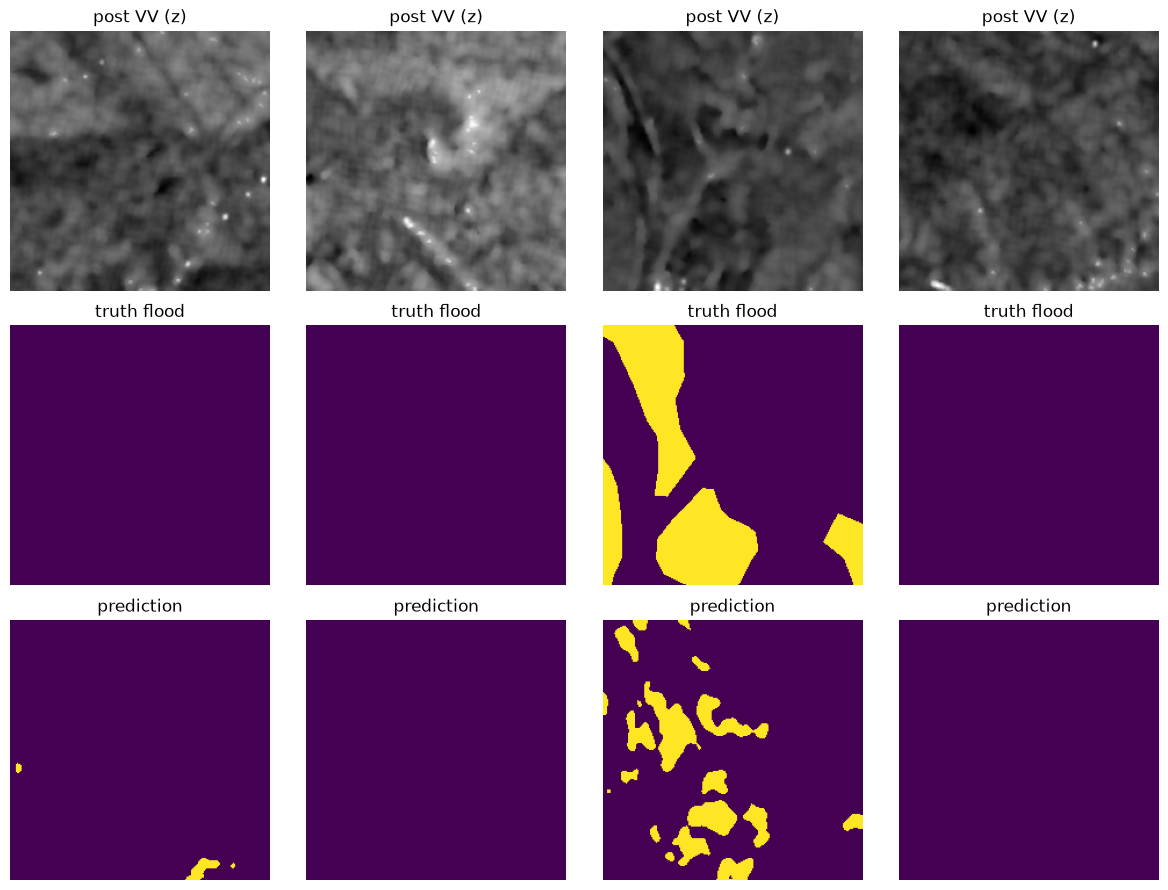

In [9]:
STATS = load_json(OUT_DIR / "norm_stats.json"); META = load_json(OUT_DIR / "model_meta.json"); TF = make_transform(STATS)
model = build_model(False)
model.load_state_dict(torch.load(OUT_DIR / "best_model.pth", map_location=DEVICE, weights_only=True))

test_shards = sorted(TEST_DIR.glob("*.tar"))
if not test_shards: raise FileNotFoundError(f"No .tar in {TEST_DIR}")
test_loader = torch.utils.data.DataLoader(TarShardDataset(test_shards, TF), batch_size=BATCH, num_workers=0)
tm = evaluate(model, test_loader, thresholds=np.array([0.5, META["threshold"]]))
chosen = tm[1]
R["kuro_siwo_test"] = dict(threshold=chosen["threshold"], iou=chosen["iou"], f1=chosen["f1"],
                           precision=chosen["precision"], recall=chosen["recall"], at_0p5=tm[0],
                           note="Held-out Kuro Siwo test (NOT Himalayan). Himalayan generalization is scored in Cell 14.")
save_results()
print("Kuro Siwo TEST @thr", chosen["threshold"])
for k in ["iou", "f1", "precision", "recall"]: print(f"  {k:9s}: {chosen[k]:.4f}")

# quick qualitative look
import matplotlib.pyplot as plt
model.eval(); xb, yb, vb = next(iter(test_loader))
with torch.no_grad(): pb = torch.sigmoid(model(xb.to(DEVICE))).cpu()
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for i in range(4):
    ax[0, i].imshow(xb[i, 4], cmap="gray"); ax[0, i].set_title("post VV (z)")
    ax[1, i].imshow(yb[i, 0]); ax[1, i].set_title("truth flood")
    ax[2, i].imshow(pb[i, 0] >= META["threshold"]); ax[2, i].set_title("prediction")
    for r in range(3): ax[r, i].axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "kuro_siwo_examples.png", dpi=130); plt.show()

In [8]:
from shapely.geometry import box, shape
from shapely.ops import unary_union
import planetary_computer as pc
from pystac_client import Client
import os
import time
import requests
from pathlib import Path

EVENT = date.fromisoformat(EVENT_DATE)
GRID = make_grid(AOI_BBOX, GRID_RES)
AOI = box(*AOI_BBOX)

print(
    f"Grid: EPSG:{GRID['epsg']} "
    f"{GRID['width']}x{GRID['height']} px @ {GRID_RES} m"
)

# Optional manual fallback
MANUAL_FILES = {}

# ------------------------------------------------------------
# FIX: robust raster reader
# ------------------------------------------------------------

CACHE_DIR = Path(OUT_DIR) / "_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def read_to_grid_robust(href, grid, resampling=Resampling.bilinear, name="asset"):
    # First try normal remote read
    for attempt in range(3):
        try:
            with rasterio.open(href) as src:
                with WarpedVRT(
                    src,
                    crs=grid["crs"],
                    transform=grid["transform"],
                    width=grid["width"],
                    height=grid["height"],
                    resampling=resampling,
                    src_nodata=src.nodata,
                    nodata=np.nan,
                    dtype="float32"
                ) as vrt:
                    return vrt.read(1)

        except RasterioIOError as e:
            print(f"Remote read failed for {name}, retry {attempt+1}/3")
            time.sleep(2)

    # If remote COG is broken, download it completely
    local = CACHE_DIR / f"{name}.tif"

    if not local.exists():
        print(f"Downloading locally: {name}")
        r = requests.get(href, timeout=300)
        r.raise_for_status()
        local.write_bytes(r.content)

    print(f"Reading local copy: {name}")

    with rasterio.open(local) as src:
        with WarpedVRT(
            src,
            crs=grid["crs"],
            transform=grid["transform"],
            width=grid["width"],
            height=grid["height"],
            resampling=resampling,
            src_nodata=src.nodata,
            nodata=np.nan,
            dtype="float32"
        ) as vrt:
            return vrt.read(1)


def read_list(hrefs, resampling=Resampling.bilinear, prefix="asset"):
    out = None

    for i, h in enumerate(hrefs):
        a = read_to_grid_robust(
            h,
            GRID,
            resampling,
            f"{prefix}_{i}"
        )

        out = a if out is None else np.where(np.isnan(out), a, out)

    return out


def clean_lin(a):
    a = a.astype(np.float32).copy()
    a[~np.isfinite(a) | (a <= 0)] = np.nan
    return a


def fill_nan_nearest(a):
    if np.isnan(a).all():
        raise RuntimeError("DEM is all NaN")

    idx = ndi.distance_transform_edt(
        np.isnan(a),
        return_distances=False,
        return_indices=True
    )

    return a[tuple(idx)]


acq = {
    "event_date": EVENT_DATE,
    "aoi_bbox": AOI_BBOX
}

if MANUAL_FILES:

    bands = {
        k: read_to_grid_robust(p, GRID, name=k)
        for k, p in MANUAL_FILES.items()
    }

    pre1_vv, pre1_vh, pre2_vv, pre2_vh, post_vv, post_vh = [
        clean_lin(bands[k])
        for k in [
            "pre1_vv",
            "pre1_vh",
            "pre2_vv",
            "pre2_vh",
            "post_vv",
            "post_vh"
        ]
    ]

    dem = fill_nan_nearest(bands["dem"])
    acq["source"] = "manual files"

else:

    cat = Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=pc.sign_inplace
    )

    rng = (
        f"{EVENT - timedelta(days=PRE_WINDOW_DAYS)}"
        f"/"
        f"{EVENT + timedelta(days=POST_WINDOW_DAYS)}"
    )

    items = list(
        cat.search(
            collections=["sentinel-1-rtc"],
            bbox=AOI_BBOX,
            datetime=rng
        ).items()
    )

    print("S1 RTC items found:", len(items))

    groups = {}

    for it in items:
        if "vv" not in it.assets or "vh" not in it.assets:
            continue

        k = (
            it.properties.get("sat:relative_orbit"),
            it.properties.get("sat:orbit_state"),
            it.datetime.date()
        )

        groups.setdefault(k, []).append(it)

    cov = lambda its: (
        unary_union([shape(i.geometry) for i in its])
        .intersection(AOI).area / AOI.area
    )

    groups = {
        k: v
        for k, v in groups.items()
        if cov(v) >= 0.95
    }

    tracks = {}

    for (orb, state, d), its in groups.items():
        tracks.setdefault((orb, state), []).append((d, its))

    cands = []

    for tr, lst in tracks.items():

        lst.sort(key=lambda t: t[0])

        pre = [t for t in lst if t[0] < EVENT]

        post = [
            t for t in lst
            if t[0] >= EVENT + timedelta(days=POST_MIN_OFFSET_DAYS)
        ]

        print("track", tr, "dates:", [str(t[0]) for t in lst])

        if len(pre) >= 2 and post:
            cands.append(
                dict(
                    track=tr,
                    pre=pre[-2:],
                    post=post[0],
                    delay=(post[0][0] - EVENT).days,
                    pre_gap=(EVENT - pre[-1][0]).days
                )
            )

    if not cands:
        raise RuntimeError(
            "No orbit track has >=2 pre-event and >=1 post-event scenes "
            "covering the AOI."
        )

    best = min(
        cands,
        key=lambda c: (c["delay"], c["pre_gap"])
    )

    (d1, its1), (d2, its2), (dp, itsp) = (
        best["pre"][0],
        best["pre"][1],
        best["post"]
    )

    print(
        f"Chosen track {best['track']}: "
        f"pre {d1}, {d2} | post {dp}"
    )

    rd = lambda its, a, name: clean_lin(
        read_list(
            [i.assets[a].href for i in its],
            prefix=name
        )
    )

    pre1_vv = rd(its1, "vv", "pre1_vv")
    pre1_vh = rd(its1, "vh", "pre1_vh")

    pre2_vv = rd(its2, "vv", "pre2_vv")
    pre2_vh = rd(its2, "vh", "pre2_vh")

    post_vv = rd(itsp, "vv", "post_vv")
    post_vh = rd(itsp, "vh", "post_vh")

    dem_items = list(
        cat.search(
            collections=["cop-dem-glo-30"],
            bbox=AOI_BBOX
        ).items()
    )

    dem = fill_nan_nearest(
        read_list(
            [i.assets["data"].href for i in dem_items],
            prefix="dem"
        )
    )

    acq.update(
        source="Microsoft Planetary Computer: sentinel-1-rtc, cop-dem-glo-30",
        relative_orbit=best["track"][0],
        orbit_state=best["track"][1],
        pre_dates=[str(d1), str(d2)],
        post_date=str(dp),
        same_track=True,
        scene_ids=dict(
            pre1=[i.id for i in its1],
            pre2=[i.id for i in its2],
            post=[i.id for i in itsp]
        )
    )


STACK = np.stack(
    [
        pre1_vv,
        pre1_vh,
        pre2_vv,
        pre2_vh,
        post_vv,
        post_vh,
        dem
    ]
).astype(np.float32)

save_geotiff(
    OUT_DIR / "s1_stack_linear.tif",
    STACK,
    GRID,
    nodata=np.nan
)

R["acquisition"] = acq
save_results()

print(
    "Valid post-VV fraction:",
    float(np.isfinite(post_vv).mean())
)

Grid: EPSG:32645 2999x3588 px @ 10 m
S1 RTC items found: 20
track (85, 'ascending') dates: ['2026-06-29', '2026-07-11', '2026-07-23', '2026-08-04', '2026-08-16', '2026-08-28', '2026-09-09']
track (19, 'descending') dates: ['2026-07-07', '2026-07-19', '2026-07-31', '2026-08-12', '2026-08-24', '2026-09-05']
Chosen track (85, 'ascending'): pre 2026-08-04, 2026-08-16 | post 2026-08-28
Valid post-VV fraction: 1.0


Running tiled inference...
AI flood extent: 0.130 km² in 12 polygons | baseline: 0.101 km²


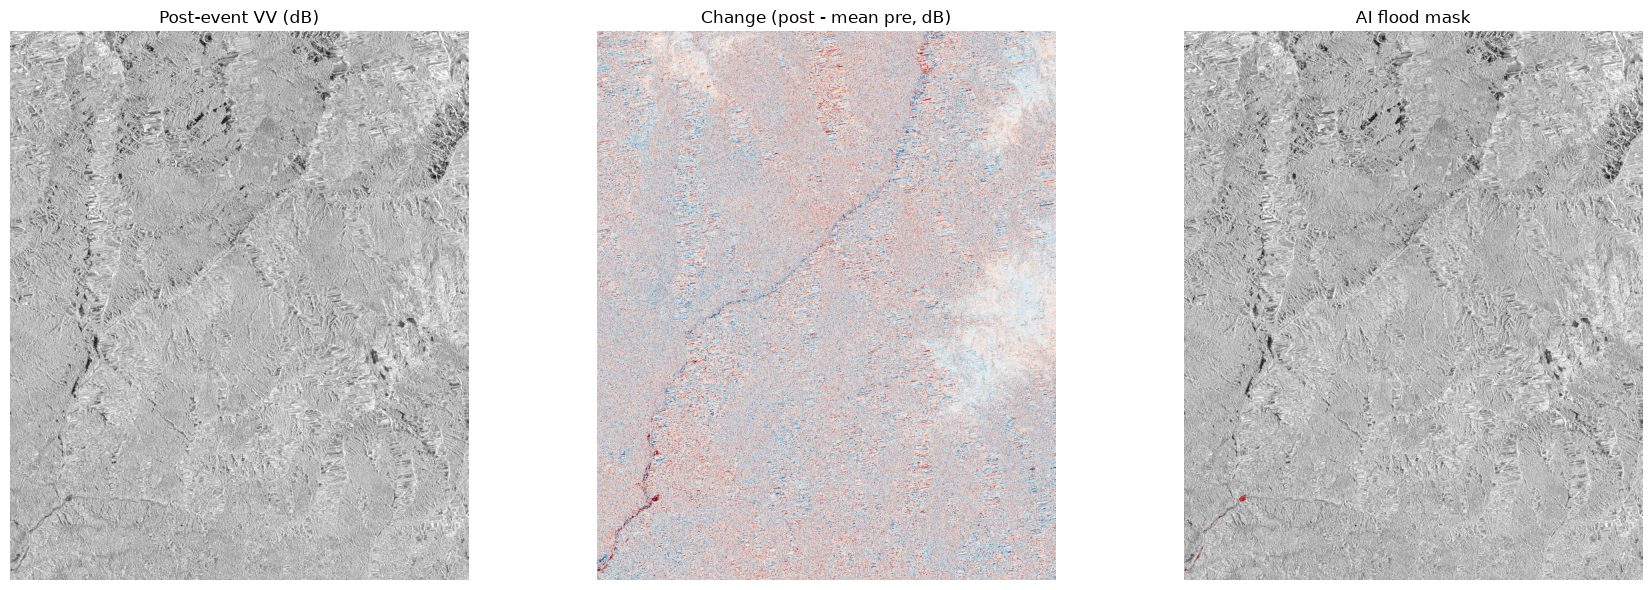

In [11]:
import geopandas as gpd
import matplotlib.pyplot as plt
STATS = load_json(OUT_DIR / "norm_stats.json"); META = load_json(OUT_DIR / "model_meta.json")
THR = META["threshold"]
model = build_model(False)
model.load_state_dict(torch.load(OUT_DIR / "best_model.pth", map_location=DEVICE, weights_only=True)); model.eval()

if "STACK" not in globals():
    STACK, GRID = read_tif(OUT_DIR / "s1_stack_linear.tif")
db = lambda a: np.where(a > 0, 10 * np.log10(np.where(a > 0, a, 1)), np.nan)

# same preprocessing as training
X = STACK.copy()
for i in range(6): X[i] = lin_to_domain(STACK[i], STATS["sar_mode"])
valid = np.isfinite(X[:6]).all(0)
Z = normalize(X, STATS)

@torch.no_grad()
def tiled_predict(model, z, valid, tile=224, stride=168, bs=8):
    C, H, W = z.shape
    pad = lambda L: tile if L <= tile else math.ceil((L - tile) / stride) * stride + tile
    ph, pw = pad(H), pad(W)
    zp = np.pad(z, ((0, 0), (0, ph - H), (0, pw - W))); vp = np.pad(valid, ((0, ph - H), (0, pw - W)))
    prob = np.zeros((ph, pw), np.float32); wsum = np.zeros((ph, pw), np.float32)
    w2 = (np.outer(np.hanning(tile), np.hanning(tile)) + 1e-3).astype(np.float32)
    coords = [(r, c) for r in range(0, ph - tile + 1, stride) for c in range(0, pw - tile + 1, stride)
              if vp[r:r + tile, c:c + tile].any()]
    for i in range(0, len(coords), bs):
        chunk = coords[i:i + bs]
        xb = torch.from_numpy(np.stack([zp[:, r:r + tile, c:c + tile] for r, c in chunk])).to(DEVICE)
        pb = torch.sigmoid(model(xb)).cpu().numpy()[:, 0]
        for (r, c), p in zip(chunk, pb):
            prob[r:r + tile, c:c + tile] += p * w2; wsum[r:r + tile, c:c + tile] += w2
    return (prob / np.maximum(wsum, 1e-6))[:H, :W]

print("Running tiled inference...")
PROB = tiled_predict(model, Z, valid)

# ---- rule-based post-processing (fixed a priori; limits false positives in steep Himalayan terrain) ----
pre1_db, pre2_db, post_db = db(STACK[0]), db(STACK[2]), db(STACK[4])
gy, gx = np.gradient(STACK[6].astype(np.float32), GRID["res"])
slope = np.degrees(np.arctan(np.hypot(gx, gy)))
dark_pre = (pre1_db < PRE_DARK_DB) & (pre2_db < PRE_DARK_DB)    # permanent water + radar shadow
steep = slope > SLOPE_MAX_DEG

def remove_small(mask, min_px):
    lab, n = ndi.label(mask, structure=np.ones((3, 3)))
    if n == 0: return mask
    keep = np.bincount(lab.ravel()) >= min_px; keep[0] = False
    return keep[lab]
def finalize(raw):
    m = raw & valid; n0 = int(m.sum())
    m = m & ~dark_pre; n1 = int(m.sum())
    m = m & ~steep; n2 = int(m.sum())
    m = remove_small(m, MIN_AREA_PX)
    return m, dict(raw_px=n0, after_pre_water_filter=n1, after_slope_filter=n2, final_px=int(m.sum()))

FLOOD_AI, st_ai = finalize(PROB >= THR)
chg = post_db - np.nanmean([pre1_db, pre2_db], axis=0)
FLOOD_BASE, st_base = finalize((chg < BASELINE_DROP_DB) & (post_db < BASELINE_POST_DB))

def polygonize(mask, layer):
    geoms = [shape(g) for g, v in rasterio.features.shapes(mask.astype(np.uint8), mask=mask.astype(bool),
                                                           transform=GRID["transform"]) if v == 1]
    gdf = gpd.GeoDataFrame({"area_ha": [g.area / 1e4 for g in geoms]}, geometry=geoms, crs=GRID["crs"])
    if len(gdf): gdf.to_file(OUT_DIR / "flood.gpkg", layer=layer, driver="GPKG")
    return gdf
if (OUT_DIR / "flood.gpkg").exists(): os.remove(OUT_DIR / "flood.gpkg")
gdf_ai, gdf_base = polygonize(FLOOD_AI, "flood_ai"), polygonize(FLOOD_BASE, "flood_baseline")

save_geotiff(OUT_DIR / "flood_prob.tif", PROB.astype(np.float32), GRID, nodata=np.nan)
save_geotiff(OUT_DIR / "flood_ai.tif", FLOOD_AI.astype(np.uint8), GRID, nodata=255)
save_geotiff(OUT_DIR / "flood_baseline.tif", FLOOD_BASE.astype(np.uint8), GRID, nodata=255)

px_km2 = GRID["res"] ** 2 / 1e6
R["flood_ai"] = dict(threshold=THR, area_km2=st_ai["final_px"] * px_km2, n_polygons=len(gdf_ai),
                     valid_area_km2=float(valid.sum()) * px_km2, filters=st_ai)
R["flood_baseline"] = dict(area_km2=st_base["final_px"] * px_km2, filters=st_base)
save_results()
print(f"AI flood extent: {R['flood_ai']['area_km2']:.3f} km² in {len(gdf_ai)} polygons | baseline: {R['flood_baseline']['area_km2']:.3f} km²")

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(post_db, cmap="gray", vmin=-25, vmax=0); ax[0].set_title("Post-event VV (dB)")
ax[1].imshow(chg, cmap="RdBu", vmin=-6, vmax=6); ax[1].set_title("Change (post - mean pre, dB)")
ax[2].imshow(post_db, cmap="gray", vmin=-25, vmax=0); ax[2].imshow(np.ma.masked_where(~FLOOD_AI, FLOOD_AI), cmap="autumn", alpha=0.8)
ax[2].set_title("AI flood mask")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig_flood_map.png", dpi=130); plt.show()

In [12]:
DEBRIS_BUFFER_M, NDVI_PRE_MIN, NDVI_DROP, NDWI_WATER = 300, 0.4, 0.3, 0.1
if "FLOOD_AI" not in globals(): FLOOD_AI = read_tif(OUT_DIR / "flood_ai.tif")[0][0].astype(bool)
if "cat" not in globals():
    cat = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)

def s2_best(start, end):
    its = list(cat.search(collections=["sentinel-2-l2a"], bbox=AOI_BBOX, datetime=f"{start}/{end}",
                          query={"eo:cloud_cover": {"lt": 80}}).items())
    g = {}
    for it in its: g.setdefault(it.datetime.date(), []).append(it)
    g = {d: v for d, v in g.items() if unary_union([shape(i.geometry) for i in v]).intersection(AOI).area / AOI.area >= 0.9}
    if not g: return None, None
    d = min(g, key=lambda k: np.mean([i.properties.get("eo:cloud_cover", 100) for i in g[k]]))
    return d, g[d]

def s2_read(its):
    out = {}
    for band in ["B03", "B04", "B08", "SCL"]:
        arr = None
        for it in its:
            a = read_to_grid(it.assets[band].href, GRID, Resampling.nearest if band == "SCL" else Resampling.bilinear)
            a[a <= 0] = np.nan
            if band != "SCL":
                rb = (it.assets[band].extra_fields.get("raster:bands") or [{}])[0]
                off = rb.get("offset", -0.1 if it.datetime.date() >= date(2022, 1, 25) else 0.0)
                a = a * rb.get("scale", 1e-4) + off
            arr = a if arr is None else np.where(np.isnan(arr), a, arr)
        out[band] = arr
    return out

d_pre, its_pre = s2_best(EVENT - timedelta(days=30), EVENT - timedelta(days=1))
d_post, its_post = s2_best(EVENT + timedelta(days=1), EVENT + timedelta(days=POST_WINDOW_DAYS))
if its_pre is None or its_post is None:
    R["sentinel2"] = dict(available=False, note="No sufficiently cloud-free full-coverage Sentinel-2 pair found.")
    print("Sentinel-2: not available for this AOI/window. (Expected limitation in monsoon.)")
else:
    A, B = s2_read(its_pre), s2_read(its_post)
    clear = lambda s: np.isin(s, [4, 5, 6, 7])
    ndvi = lambda d: (d["B08"] - d["B04"]) / (d["B08"] + d["B04"] + 1e-6)
    ndwi = lambda d: (d["B03"] - d["B08"]) / (d["B03"] + d["B08"] + 1e-6)
    ok = clear(A["SCL"]) & clear(B["SCL"])
    water_new = (ndwi(B) > NDWI_WATER) & ~(ndwi(A) > NDWI_WATER) & ok
    near_flood = ndi.distance_transform_edt(~FLOOD_AI) * GRID["res"] <= DEBRIS_BUFFER_M
    debris = ok & (ndvi(A) > NDVI_PRE_MIN) & ((ndvi(A) - ndvi(B)) > NDVI_DROP) & ~(ndwi(B) > NDWI_WATER) & near_flood
    debris = remove_small(debris, MIN_AREA_PX)
    geoms = [shape(g) for g, v in rasterio.features.shapes(debris.astype(np.uint8), mask=debris, transform=GRID["transform"]) if v == 1]
    if geoms:
        gpd.GeoDataFrame({"area_ha": [g.area / 1e4 for g in geoms]}, geometry=geoms, crs=GRID["crs"]).to_file(
            OUT_DIR / "flood.gpkg", layer="debris_candidates", driver="GPKG")
    inter = int((FLOOD_AI & water_new).sum()); union = int(((FLOOD_AI & ok) | water_new).sum())
    R["sentinel2"] = dict(available=True, pre_date=str(d_pre), post_date=str(d_post),
                          clear_fraction=float(ok.mean()), debris_candidate_km2=float(debris.sum()) * px_km2,
                          s2_new_water_km2=float(water_new.sum()) * px_km2,
                          ai_vs_s2_new_water_iou_on_clear_px=inter / max(union, 1),
                          note="Debris layer = vegetation-loss/sediment heuristic near the AI flood mask; not a trained model.")
    print(R["sentinel2"])
save_results()

{'available': True, 'pre_date': '2026-08-12', 'post_date': '2026-08-27', 'clear_fraction': 0.2595619944663829, 'debris_candidate_km2': 0.9899, 's2_new_water_km2': 1.1736, 'ai_vs_s2_new_water_iou_on_clear_px': 0.00797769343970258, 'note': 'Debris layer = vegetation-loss/sediment heuristic near the AI flood mask; not a trained model.'}


In [15]:
%pip install -U pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

import os

os.environ["OHSOME_API_KEY"] = "eyJvcmciOiI1YjNjZTM1OTc4NTExMTAwMDFjZjYyNDgiLCJpZCI6IjA0YzEzNDc0OTQ5MDQxZDA5OWQxNDMzN2NhNTVlZjZjIiwiaCI6Im11cm11cjY0In0="

In [1]:
import os, getpass
os.environ["OHSOME_API_KEY"] = getpass.getpass("Ohsome API key: ")

In [6]:
import os, json, time as time_mod
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely import wkb

# ---------------- config ----------------
OHSOME = "https://api.heigit.org/ohsome-api/v2-rc/extraction/features.parquet"
OHSOME_API_KEY = os.environ.get("OHSOME_API_KEY")
if not OHSOME_API_KEY:
    raise RuntimeError("OHSOME_API_KEY not set. Run the getpass cell above first.")

MIN_INTERVAL_S = 2.0      # minimum gap between API calls
MAX_ATTEMPTS = 6          # per tile
REFETCH = False           # True = ignore osm_*.geojson (tile cache is still used)

ROAD_CLASSES = ("motorway,motorway_link,trunk,trunk_link,primary,primary_link,secondary,secondary_link,"
                "tertiary,tertiary_link,unclassified,residential,service,living_street,track")
OSM_QUERIES = {
    "buildings": "building=* and building!=no and geometry:polygon",
    "roads":     f"highway in ({ROAD_CLASSES}) and geometry:line",
    "bridges":   "bridge=* and bridge!=no and geometry:line",
    "hospitals": "(amenity=hospital or healthcare=hospital or amenity=clinic) and (geometry:point or geometry:polygon)",
    "places":    "place in (city,town,village,hamlet) and geometry:point",
}
# degrees per request: big tiles for sparse layers = fewer calls = fewer 429s
TILE_STEPS = {"buildings": 0.15, "roads": 0.15, "bridges": 0.5, "hospitals": 0.5, "places": 0.5}
# columns later cells rely on; a cached file missing these gets refetched
REQUIRED_COLS = {"buildings": [], "roads": ["highway", "bridge"], "bridges": [], "hospitals": [], "places": ["place"]}
KEEP_TAGS = ["building", "highway", "bridge", "name", "amenity", "healthcare", "place", "man_made"]

CACHE_DIR = OUT_DIR / "osm_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
_last_call = [0.0]
_printed_cols = set()


def empty_gdf():
    return gpd.GeoDataFrame(geometry=[], crs="EPSG:4326")


def tile_list(bbox, step):
    lon0, lat0, lon1, lat1 = bbox
    tiles = []
    for x in np.arange(lon0, lon1 - 1e-9, step):
        for y in np.arange(lat0, lat1 - 1e-9, step):
            tiles.append([round(float(x), 5), round(float(y), 5),
                          round(float(min(x + step, lon1)), 5), round(float(min(y + step, lat1)), 5)])
    return tiles


def fetch_tile_bytes(aoi, flt, t):
    """POST one tile. Returns parquet bytes, b'' if empty, or None if all attempts failed."""
    payload = {"aoi": aoi, "filter": flt, "time": t, "clip": False}
    headers = {"Authorization": OHSOME_API_KEY, "Content-Type": "application/json"}
    for attempt in range(MAX_ATTEMPTS):
        gap = MIN_INTERVAL_S - (time_mod.time() - _last_call[0])
        if gap > 0:
            time_mod.sleep(gap)
        try:
            r = requests.post(OHSOME, json=payload, headers=headers, timeout=(15, 600))
        except requests.RequestException as e:
            _last_call[0] = time_mod.time()
            delay = min(60, 5 * 2 ** attempt)
            print(f"    network error ({e.__class__.__name__}); retry in {delay}s [{attempt + 1}/{MAX_ATTEMPTS}]")
            time_mod.sleep(delay)
            continue
        _last_call[0] = time_mod.time()
        if r.status_code == 200:
            return r.content
        if r.status_code == 429 or r.status_code >= 500:
            ra = r.headers.get("Retry-After", "")
            delay = float(ra) if ra.replace(".", "", 1).isdigit() else min(120, 10 * 2 ** attempt)
            print(f"    HTTP {r.status_code}; waiting {delay:.0f}s [{attempt + 1}/{MAX_ATTEMPTS}]")
            time_mod.sleep(delay)
            continue
        raise RuntimeError(f"HTTP {r.status_code}: {r.text[:300]}")     # 400/401/403 etc: real error, don't loop
    return None


def tags_to_dict(v):
    if v is None:
        return {}
    if isinstance(v, dict):
        return v
    if isinstance(v, str):
        try:
            return json.loads(v)
        except Exception:
            return {}
    try:
        return dict(v)            # list/array of (key, value) pairs (parquet map type)
    except Exception:
        return {}


def parse_tile(content, name):
    df = pd.read_parquet(BytesIO(content))
    if df.empty:
        return None
    if name not in _printed_cols:
        print(f"    [{name}] parquet columns: {list(df.columns)}")
        _printed_cols.add(name)
    gcol = "geom" if "geom" in df.columns else ("geometry" if "geometry" in df.columns else None)
    if gcol is None:
        raise KeyError(f"No geometry column in {list(df.columns)}")

    def to_geom(v):
        if v is None:
            return None
        if isinstance(v, str):
            return wkb.loads(v, hex=True)
        return wkb.loads(bytes(v))
    geoms = [to_geom(v) for v in df[gcol]]

    # flatten tags -> columns used downstream
    if "tags" in df.columns:
        td = [tags_to_dict(v) for v in df["tags"]]
        for k in KEEP_TAGS:
            if k not in df.columns:
                df[k] = [d.get(k) for d in td]
    # stable id column
    if "@osmId" not in df.columns:
        if "osm_type" in df.columns and "osm_id" in df.columns:
            df["@osmId"] = df["osm_type"].astype(str) + "/" + df["osm_id"].astype(str)
        elif "osm_id" in df.columns:
            df["@osmId"] = df["osm_id"].astype(str)
    keep = [c for c in ["@osmId"] + KEEP_TAGS if c in df.columns]
    out = gpd.GeoDataFrame(df[keep].copy(), geometry=geoms, crs="EPSG:4326")
    return out[out.geometry.notna()]


def fetch_category(name, flt):
    """Returns (GeoDataFrame, complete_flag). Finished tiles are cached on disk and reused."""
    tiles = tile_list(AOI_BBOX, TILE_STEPS[name])
    parts, pending = [], list(tiles)
    for rnd in range(2):                              # second round retries failed tiles after a cool-down
        failed = []
        for aoi in pending:
            cp = CACHE_DIR / f"{name}_{aoi[0]}_{aoi[1]}_{aoi[2]}_{aoi[3]}_{OSM_TIME}.parquet"
            if cp.exists():
                content = cp.read_bytes()
            else:
                print(f"  [{name}] tile {tiles.index(aoi) + 1}/{len(tiles)} {aoi}")
                content = fetch_tile_bytes(aoi, OSM_QUERIES[name], OSM_TIME)
                if content is None:
                    failed.append(aoi)
                    continue
                cp.write_bytes(content)
            if content:
                g = parse_tile(content, name)
                if g is not None:
                    parts.append(g)
        pending = failed
        if not pending:
            break
        if rnd == 0:
            print(f"  [{name}] {len(pending)} tile(s) failed; cooling down 90s then retrying once...")
            time_mod.sleep(90)
    if not parts:
        return empty_gdf(), not pending
    gdf = pd.concat(parts, ignore_index=True)
    gdf = gpd.GeoDataFrame(gdf, geometry="geometry", crs="EPSG:4326")
    if "@osmId" in gdf.columns:
        gdf = gdf.drop_duplicates(subset=["@osmId"])
    else:
        gdf = gdf.assign(_w=gdf.geometry.to_wkb()).drop_duplicates("_w").drop(columns="_w")
    return gdf.reset_index(drop=True), not pending


# ---------------- run ----------------
OSM, incomplete = {}, []
for name in OSM_QUERIES:
    p = OUT_DIR / f"osm_{name}.geojson"
    use_cache = p.exists() and not REFETCH
    if use_cache:
        g = gpd.read_file(p)
        miss = [c for c in REQUIRED_COLS[name] if c not in g.columns]
        if miss:
            print(f"Cached {name} lacks columns {miss}; refetching.")
            use_cache = False
        else:
            print(f"Loaded cached {name}")
            OSM[name] = g
    if not use_cache:
        print(f"Fetching {name} ...")
        g, ok = fetch_category(name, OSM_QUERIES[name])
        OSM[name] = g
        if not ok:
            incomplete.append(name)
        elif len(g):
            g.to_file(p, driver="GeoJSON")
    print(f"  {name}: {len(OSM[name])} features")

if incomplete:
    raise RuntimeError(f"Incomplete layers: {incomplete}. Wait a few minutes (rate limit) and re-run this cell; "
                       f"finished tiles are cached in {CACHE_DIR}.")

R["osm"] = dict(snapshot=OSM_TIME, counts={k: len(v) for k, v in OSM.items()}, attribution=ATTR["osm"])
save_results()
print("OSM ready:", R["osm"]["counts"])

Loaded cached buildings
  buildings: 48893 features
Cached roads lacks columns ['highway', 'bridge']; refetching.
Fetching roads ...
  [roads] tile 1/6 [85.15, 27.93, 85.3, 28.08]
    [roads] parquet columns: ['osm_type', 'osm_id', 'edit_timestamp', 'valid_to_timestamp', 'version', 'minor_version', 'edits', 'user_id', 'user_name', 'changeset_id', 'tags', 'bbox', 'geom_type', 'geom', 'clipped']
  [roads] tile 2/6 [85.15, 28.08, 85.3, 28.23]
  [roads] tile 3/6 [85.15, 28.23, 85.3, 28.25]
  [roads] tile 4/6 [85.3, 27.93, 85.45, 28.08]
  [roads] tile 5/6 [85.3, 28.08, 85.45, 28.23]
  [roads] tile 6/6 [85.3, 28.23, 85.45, 28.25]
  roads: 1133 features
Fetching bridges ...
  [bridges] tile 1/1 [85.15, 27.93, 85.45, 28.25]
    [bridges] parquet columns: ['osm_type', 'osm_id', 'edit_timestamp', 'valid_to_timestamp', 'version', 'minor_version', 'edits', 'user_id', 'user_name', 'changeset_id', 'tags', 'bbox', 'geom_type', 'geom', 'clipped']
  bridges: 123 features
Fetching hospitals ...
  [hospi

In [9]:
import shapely
from shapely.ops import unary_union
FL = gpd.read_file(OUT_DIR / "flood.gpkg", layer="flood_ai")
if not len(FL): raise RuntimeError("No AI flood polygons; nothing to overlay.")
BUF = max(SCENARIOS.values())
flood_in = unary_union(FL.geometry); flood_near = flood_in.buffer(BUF if BUF > 0 else 25)
shapely.prepare(flood_in); shapely.prepare(flood_near)

def classify(gdf):
    g = gdf.to_crs(GRID["crs"]).copy()
    inside = g.intersects(flood_in); near = g.intersects(flood_near) & ~inside
    g["status"] = np.where(inside, "inside", np.where(near, "near", "outside"))
    return g
def slim(g, cols):
    return g[[c for c in cols if c in g.columns] + ["geometry"]].copy()

imp = {}
infra_path = OUT_DIR / "infra.gpkg"
if infra_path.exists(): os.remove(infra_path)

b = classify(OSM["buildings"]) if len(OSM["buildings"]) else None
if b is not None:
    imp.update(buildings_total=len(b), buildings_inside=int((b.status == "inside").sum()), buildings_near=int((b.status == "near").sum()))
    slim(b[b.status != "outside"], ["@osmId", "building", "name", "status"]).to_file(infra_path, layer="buildings_affected", driver="GPKG")

r = classify(OSM["roads"]) if len(OSM["roads"]) else None
if r is not None:
    ins = r[r.status == "inside"]
    imp.update(roads_total_km=float(r.length.sum() / 1000), roads_segments_inside=len(ins), roads_segments_near=int((r.status == "near").sum()),
               roads_km_inside_flood=float(ins.geometry.intersection(flood_in).length.sum() / 1000))
    slim(r[r.status != "outside"], ["@osmId", "highway", "name", "bridge", "status"]).to_file(infra_path, layer="roads_affected", driver="GPKG")

br = classify(OSM["bridges"]) if len(OSM["bridges"]) else None
if br is not None:
    imp.update(bridges_total=len(br), bridges_inside=int((br.status == "inside").sum()), bridges_near=int((br.status == "near").sum()),
               bridge_names_potentially_affected=[str(n) for n in br[br.status != "outside"].get("name", pd.Series([], dtype=object)).dropna().unique()][:15])
    slim(br, ["@osmId", "bridge", "highway", "name", "status"]).to_file(infra_path, layer="bridges", driver="GPKG")

for k in ["hospitals", "places"]:
    if len(OSM[k]): slim(OSM[k].to_crs(GRID["crs"]), ["@osmId", "name", "amenity", "place"]).to_file(infra_path, layer=k, driver="GPKG")
imp["note"] = "'inside'/'near' = intersects predicted flood extent / within buffer. This is potential exposure, not confirmed damage."
R["impact"] = imp; save_results(); print(json.dumps(imp, indent=2, default=str))

{
  "buildings_total": 48893,
  "buildings_inside": 11,
  "buildings_near": 36,
  "roads_total_km": 962.9736167909956,
  "roads_segments_inside": 3,
  "roads_segments_near": 6,
  "roads_km_inside_flood": 0.11084882299469351,
  "bridges_total": 123,
  "bridges_inside": 2,
  "bridges_near": 1,
  "bridge_names_potentially_affected": [
    "Suspension Bridge",
    "Falaakhu River Bridge",
    "Tupche Aama ko pool"
  ],
  "note": "'inside'/'near' = intersects predicted flood extent / within buffer. This is potential exposure, not confirmed damage."
}


In [10]:
import networkx as nx
from scipy.spatial import cKDTree
from shapely.geometry import LineString, Point
from sklearn.cluster import DBSCAN

roads = OSM["roads"].to_crs(GRID["crs"]) if len(OSM["roads"]) else None
if roads is None: raise RuntimeError("No roads in OSM for this AOI.")
isb = lambda v: isinstance(v, str) and v not in ("no", "")

# graph with real OSM topology: nodes = shared vertices, edges = consecutive vertex pairs
G = nx.Graph()
for _, row in roads.iterrows():
    geom = row.geometry; parts = list(geom.geoms) if geom.geom_type.startswith("Multi") else [geom]
    bridge = isb(row.get("bridge"))
    for g in parts:
        c = [(round(x, 2), round(y, 2)) for x, y in g.coords]
        for a, b2 in zip(c[:-1], c[1:]):
            if a != b2 and not G.has_edge(a, b2):
                G.add_edge(a, b2, length=math.hypot(b2[0] - a[0], b2[1] - a[1]), bridge=bridge)
edges = list(G.edges(data=True))
seg_arr = np.array([LineString([a, b2]) for a, b2, _ in edges], dtype=object)
nodes = list(G.nodes); tree = cKDTree(np.array(nodes))
print(f"Road graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

def snap(pt):
    d, i = tree.query([pt.x, pt.y]); return nodes[i] if d <= SNAP_MAX_M else None
to_utm = Transformer.from_crs(4326, GRID["epsg"], always_xy=True)

# destinations
targets = []   # (name, type, node)
def add_targets(gdf, typ):
    if not len(gdf): return
    g = gdf.to_crs(GRID["crs"])
    for nm, geom in zip(g.get("name", pd.Series([None] * len(g))), g.geometry.centroid):
        n = snap(geom)
        if n is not None: targets.append((nm or typ, typ, n))
add_targets(OSM["hospitals"], "hospital")
pl = OSM["places"]
add_targets(pl[pl["place"].isin(["city", "town"])] if len(pl) and "place" in pl.columns else pl, "town")
for nm, lon, lat in RESPONSE_POINTS:
    x, y = to_utm.transform(lon, lat); n = snap(Point(x, y))
    if n is not None: targets.append((nm, "response", n))
print("Destinations snapped:", pd.Series([t[1] for t in targets]).value_counts().to_dict() if targets else "NONE (hospital/town not in OSM here; add RESPONSE_POINTS)")

# settlements = OSM village/hamlet nodes, fallback: building clusters
sett = []
if len(pl) and "place" in pl.columns:
    v = pl[pl["place"].isin(["village", "hamlet"])].to_crs(GRID["crs"])
    sett = [(nm or f"settlement_{i}", g) for i, (nm, g) in enumerate(zip(v.get("name", pd.Series([None] * len(v))), v.geometry))]
if len(sett) < 3 and len(OSM["buildings"]):
    cen = OSM["buildings"].to_crs(GRID["crs"]).geometry.centroid
    xy = np.array([[p.x, p.y] for p in cen])
    lab = DBSCAN(eps=200, min_samples=8).fit_predict(xy)
    sett = [(f"building_cluster_{k}", Point(xy[lab == k].mean(0))) for k in sorted(set(lab)) if k != -1]
    print("Using building clusters as settlements:", len(sett))
sdf = gpd.GeoDataFrame({"name": [s[0] for s in sett]}, geometry=[s[1] for s in sett], crs=GRID["crs"])
sdf["node"] = [snap(g) for g in sdf.geometry]
print("Settlements:", len(sdf), "| snapped to road network:", int(sdf.node.notna().sum()))

def dist_from(Gx, srcs):
    srcs = [s for s in srcs if s in Gx]
    return nx.multi_source_dijkstra_path_length(Gx, srcs, weight="length") if srcs else {}

types = {"hospital": [t[2] for t in targets if t[1] == "hospital"], "town": [t[2] for t in targets if t[1] == "town"],
         "any": [t[2] for t in targets]}
d_before = {k: dist_from(G, v) for k, v in types.items()}
comps_b = list(nx.connected_components(G)); main_b = max(comps_b, key=len)

cut = {}
for sc, buf in SCENARIOS.items():
    zone = flood_in.buffer(buf) if buf > 0 else flood_in
    shapely.prepare(zone)
    hit = shapely.intersects(seg_arr, zone)
    removed = [(a, b2) for (a, b2, _), h in zip(edges, hit) if h]
    Ga = G.copy(); Ga.remove_edges_from(removed)
    d_after = {k: dist_from(Ga, v) for k, v in types.items()}
    comps_a = sorted(nx.connected_components(Ga), key=len, reverse=True); cid = {n: i for i, c in enumerate(comps_a) for n in c}
    cnt = dict(cut_any=0, cut_hospital=0, cut_town=0, cut_main=0, longer_route=0, connected=0, not_on_network=0)
    cols = {f"{sc}_status": [], f"{sc}_d_before_m": [], f"{sc}_d_after_m": []}
    for n in sdf.node:
        if n is None:
            cnt["not_on_network"] += 1; cols[f"{sc}_status"].append("not_on_network"); cols[f"{sc}_d_before_m"].append(None); cols[f"{sc}_d_after_m"].append(None); continue
        rb, ra = n in d_before["any"], n in d_after["any"]
        hb, ha = n in d_before["hospital"], n in d_after["hospital"]
        tb, ta = n in d_before["town"], n in d_after["town"]
        mb, ma = n in main_b, cid.get(n) == 0
        cnt["cut_hospital"] += int(hb and not ha); cnt["cut_town"] += int(tb and not ta); cnt["cut_main"] += int(mb and not ma)
        dbf, daf = d_before["any"].get(n), d_after["any"].get(n)
        if rb and not ra: s = "cut_off"; cnt["cut_any"] += 1
        elif rb and ra and daf > dbf + 50: s = "longer_route"; cnt["longer_route"] += 1
        else: s = "connected"; cnt["connected"] += 1
        cols[f"{sc}_status"].append(s); cols[f"{sc}_d_before_m"].append(dbf); cols[f"{sc}_d_after_m"].append(daf)
    for k, v in cols.items(): sdf[k] = v
    cut[sc] = dict(buffer_m=buf, edges_removed=len(removed), road_km_removed=float(sum(G.edges[e]["length"] for e in removed) / 1000),
                   bridge_edges_removed=int(sum(G.edges[e]["bridge"] for e in removed)), n_settlements=len(sdf),
                   n_destinations=len(targets), **cnt)
    print(sc, cut[sc])

out = sdf.drop(columns=["node"]).copy(); out.to_file(OUT_DIR / "settlements.gpkg", layer="settlements", driver="GPKG")
tg = gpd.GeoDataFrame({"name": [t[0] for t in targets], "type": [t[1] for t in targets]},
                      geometry=[Point(t[2]) for t in targets], crs=GRID["crs"])
if len(tg): tg.to_file(OUT_DIR / "settlements.gpkg", layer="destinations", driver="GPKG")
cut["note"] = "Estimate from pre-event OSM topology; cut_off = reachable to a destination before and unreachable after removing flooded segments."
R["cutoff"] = cut; save_results()

Road graph: 51997 nodes, 52055 edges
Destinations snapped: {'hospital': 11}
Settlements: 121 | snapped to road network: 87
inside_flood {'buffer_m': 0, 'edges_removed': 5, 'road_km_removed': 0.3598680839684824, 'bridge_edges_removed': 0, 'n_settlements': 121, 'n_destinations': 11, 'cut_any': 0, 'cut_hospital': 0, 'cut_town': 0, 'cut_main': 0, 'longer_route': 5, 'connected': 82, 'not_on_network': 34}
buffer_25m {'buffer_m': 25, 'edges_removed': 46, 'road_km_removed': 1.3485948476271894, 'bridge_edges_removed': 1, 'n_settlements': 121, 'n_destinations': 11, 'cut_any': 1, 'cut_hospital': 1, 'cut_town': 0, 'cut_main': 1, 'longer_route': 4, 'connected': 82, 'not_on_network': 34}


In [11]:
R = load_json(RES_PATH)
def g(*path, fmt="{}", default="not computed"):
    cur = R
    for p in path:
        if not isinstance(cur, dict) or p not in cur: return default
        cur = cur[p]
    try: return fmt.format(cur)
    except Exception: return str(cur)

pc_ = PRIMARY_SCENARIO
rows = f"""
<tr><td>AI flood extent</td><td>{g('flood_ai','area_km2',fmt='{:.2f}')} km² ({g('flood_ai','n_polygons')} polygons)</td></tr>
<tr><td>Baseline (SAR threshold) extent</td><td>{g('flood_baseline','area_km2',fmt='{:.2f}')} km²</td></tr>
<tr><td>Debris/sediment candidates (heuristic)</td><td>{g('sentinel2','debris_candidate_km2',fmt='{:.2f}')} km²</td></tr>
<tr><td>Buildings inside / within buffer of flood</td><td>{g('impact','buildings_inside')} / {g('impact','buildings_near')} (of {g('impact','buildings_total')})</td></tr>
<tr><td>Road segments inside flood; km inside</td><td>{g('impact','roads_segments_inside')}; {g('impact','roads_km_inside_flood',fmt='{:.1f}')} km</td></tr>
<tr><td>Bridges inside / near flood</td><td>{g('impact','bridges_inside')} / {g('impact','bridges_near')} (of {g('impact','bridges_total')})</td></tr>
<tr><td>Settlements cut off from any hospital/town/response point</td><td>{g('cutoff',pc_,'cut_any')} of {g('cutoff',pc_,'n_settlements')} (conservative {g('cutoff','buffer_25m','cut_any')})</td></tr>
<tr><td>Cut off from hospital / town / main network</td><td>{g('cutoff',pc_,'cut_hospital')} / {g('cutoff',pc_,'cut_town')} / {g('cutoff',pc_,'cut_main')}</td></tr>
<tr><td>Settlements with longer route</td><td>{g('cutoff',pc_,'longer_route')}</td></tr>
<tr><td>Kuro Siwo test IoU / F1 / P / R</td><td>{g('kuro_siwo_test','iou',fmt='{:.3f}')} / {g('kuro_siwo_test','f1',fmt='{:.3f}')} / {g('kuro_siwo_test','precision',fmt='{:.3f}')} / {g('kuro_siwo_test','recall',fmt='{:.3f}')}</td></tr>
<tr><td>EMSR927 validation IoU / F1 / P / R (AI)</td><td>{g('emsr927','ai','iou',fmt='{:.3f}')} / {g('emsr927','ai','f1',fmt='{:.3f}')} / {g('emsr927','ai','precision',fmt='{:.3f}')} / {g('emsr927','ai','recall',fmt='{:.3f}')}</td></tr>
"""
html = f"""<html><head><meta charset="utf-8"><style>
@page {{ size: A4; margin: 14mm }} body {{ font-family: Arial; font-size: 11px }} h1 {{ font-size: 18px }}
table {{ border-collapse: collapse; width: 100% }} td {{ border: 1px solid #999; padding: 3px 6px }} .small {{ font-size: 9px; color: #444 }}
</style></head><body>
<h1>Situation Report: Bhote Koshi–Trishuli flood, {EVENT_DATE}</h1>
<p><b>AOI:</b> {AOI_BBOX} | <b>Sentinel-1:</b> relative orbit {g('acquisition','relative_orbit')} ({g('acquisition','orbit_state')}),
pre {g('acquisition','pre_dates')}, post {g('acquisition','post_date')} | <b>Sentinel-2:</b> {g('sentinel2','pre_date')} → {g('sentinel2','post_date')}
| <b>OSM snapshot:</b> {OSM_TIME}</p>
<table>{rows}</table>
<p>All figures above are computed by the pipeline from the generated flood map, pre-event OSM and the road graph. "Inside/near" means potential exposure, not confirmed damage; "cut off" is a graph-connectivity estimate.</p>
<p><b>Limitations.</b> {DISCLAIMER}</p>
<p class="small">{ATTR['sentinel']}<br>{ATTR['dem']}<br>{ATTR['osm']}<br>{ATTR['kuro']}</p>
</body></html>"""
(OUT_DIR / "situation_report.html").write_text(html, encoding="utf-8")
print("Saved:", OUT_DIR / "situation_report.html", "(open in browser -> Print -> Save as PDF)")

Saved: C:\NIT KKR\after placement\iit mandi hackathon\outputs\situation_report.html (open in browser -> Print -> Save as PDF)


In [12]:
import folium, matplotlib
R = load_json(RES_PATH)
if "STACK" not in globals(): STACK, GRID = read_tif(OUT_DIR / "s1_stack_linear.tif")
db = lambda a: np.where(a > 0, 10 * np.log10(np.where(a > 0, a, 1)), np.nan)
post_db = db(STACK[4]); chg = post_db - np.nanmean([db(STACK[0]), db(STACK[2])], axis=0)

def gray(arr, lo, hi):
    t = np.nan_to_num(np.clip((arr - lo) / (hi - lo), 0, 1)); gv = (t * 255).astype(np.uint8)
    return np.dstack([gv, gv, gv, np.where(np.isfinite(arr), 255, 0).astype(np.uint8)])
def cmap_rgba(arr, lo, hi, name):
    t = np.nan_to_num(np.clip((arr - lo) / (hi - lo), 0, 1))
    rgba = (matplotlib.colormaps[name](t) * 255).astype(np.uint8); rgba[..., 3] = np.where(np.isfinite(arr), 190, 0); return rgba

lat_c, lon_c = (AOI_BBOX[1] + AOI_BBOX[3]) / 2, (AOI_BBOX[0] + AOI_BBOX[2]) / 2
m = folium.Map(location=[lat_c, lon_c], zoom_start=11, tiles=None)
folium.TileLayer("OpenStreetMap", name="OSM basemap (© OpenStreetMap contributors)").add_to(m)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                 attr="Esri World Imagery", name="Satellite basemap (Esri)", show=False).add_to(m)

for arr, nm, rgba_fn, show in [(post_db, "Sentinel-1 post-event VV", lambda a: gray(a, -25, 0), False),
                               (chg, "Sentinel-1 change (post − pre, dB)", lambda a: cmap_rgba(a, -6, 6, "RdBu"), False)]:
    a4326, (w, s, e, n) = to_wgs84(arr, GRID)
    folium.raster_layers.ImageOverlay(rgba_fn(a4326), bounds=[[s, w], [n, e]], opacity=0.8, name=nm, show=show).add_to(m)

def layer(path, lyr, name, style, show=True, tip=None):
    try: gdf = gpd.read_file(path, layer=lyr).to_crs(4326)
    except Exception: return
    if not len(gdf): return
    kw = dict(name=name, style_function=style, show=show)
    if tip: kw["tooltip"] = folium.GeoJsonTooltip(fields=[c for c in tip if c in gdf.columns])
    folium.GeoJson(gdf.to_json(), **kw).add_to(m)

fp = OUT_DIR / "flood.gpkg"; ip = OUT_DIR / "infra.gpkg"; sp = OUT_DIR / "settlements.gpkg"
layer(fp, "flood_ai", "AI flood/debris extent", lambda f: dict(color="#d7191c", weight=0.5, fillOpacity=0.55))
layer(fp, "flood_baseline", "Baseline SAR change extent", lambda f: dict(color="#fdae61", weight=0.5, fillOpacity=0.35), show=False)
layer(fp, "debris_candidates", "Debris/sediment candidates (heuristic)", lambda f: dict(color="#8c510a", weight=0.5, fillOpacity=0.5), show=False)
layer(ip, "buildings_affected", "Buildings inside/near flood",
      lambda f: dict(color="#7b3294" if f["properties"]["status"] == "inside" else "#c2a5cf", weight=1, fillOpacity=0.7), tip=["name", "status"])
layer(ip, "roads_affected", "Roads inside/near flood",
      lambda f: dict(color="#e31a1c" if f["properties"]["status"] == "inside" else "#fd8d3c", weight=3), tip=["highway", "name", "status"])
layer(ip, "bridges", "Bridges (inside/near flood highlighted)",
      lambda f: dict(color={"inside": "#000000", "near": "#ff00ff"}.get(f["properties"]["status"], "#3182bd"), weight=4), tip=["name", "status"])

try:
    S = gpd.read_file(sp, layer="settlements").to_crs(4326); fg = folium.FeatureGroup(name="Settlements (cut-off analysis)")
    colors = {"cut_off": "red", "longer_route": "orange", "connected": "green", "not_on_network": "gray"}
    for _, r in S.iterrows():
        st = r[f"{PRIMARY_SCENARIO}_status"]
        tip = f"{r['name']} | {st} | before {r[f'{PRIMARY_SCENARIO}_d_before_m']} m → after {r[f'{PRIMARY_SCENARIO}_d_after_m']} m | conservative: {r['buffer_25m_status']}"
        folium.CircleMarker([r.geometry.y, r.geometry.x], radius=6, color=colors.get(st, "blue"), fill=True, fill_opacity=0.9, tooltip=tip).add_to(fg)
    fg.add_to(m)
    D = gpd.read_file(sp, layer="destinations").to_crs(4326); fg2 = folium.FeatureGroup(name="Hospitals / towns / response points")
    for _, r in D.iterrows():
        folium.Marker([r.geometry.y, r.geometry.x], tooltip=f"{r['name']} ({r['type']})", icon=folium.Icon(color="blue", icon="plus-sign")).add_to(fg2)
    fg2.add_to(m)
except Exception as e:
    print("Settlement layers skipped:", e)

banner = f"""<div style="position:fixed;bottom:8px;left:8px;z-index:9999;background:white;padding:6px 8px;font:11px Arial;max-width:560px;border:1px solid #888">
<b>Educational prototype, not for operational emergency response.</b><br>
Flood extent: {R.get('flood_ai',{}).get('area_km2','n/a') if not isinstance(R.get('flood_ai',{}).get('area_km2'),float) else round(R['flood_ai']['area_km2'],2)} km² |
Legend: red/purple = affected, green = connected, orange = longer route, red dot = cut off<br>
{ATTR['sentinel']} {ATTR['osm']}<br><span style="font-size:9px">{ATTR['dem']}</span></div>"""
m.get_root().html.add_child(folium.Element(banner))
folium.LayerControl(collapsed=False).add_to(m)
m.save(OUT_DIR / "dashboard.html"); print("Saved", OUT_DIR / "dashboard.html")

Saved C:\NIT KKR\after placement\iit mandi hackathon\outputs\dashboard.html


In [14]:
# Download EMSR927 observed-flood-extent vectors AFTER the system has produced its outputs. Never used as input.
EMSR_FLOOD_PATH = None      # e.g. r"C:\...\EMSR927_AOI01_..._observedEventA.shp"  (or list of paths)
EMSR_AOI_PATH   = None      # strongly recommended: the EMS area-of-interest polygon layer(s), so unmapped land isn't counted as FP

if EMSR_FLOOD_PATH is None:
    print("Set EMSR_FLOOD_PATH to run validation.")
else:
    paths = EMSR_FLOOD_PATH if isinstance(EMSR_FLOOD_PATH, (list, tuple)) else [EMSR_FLOOD_PATH]
    ems = pd.concat([gpd.read_file(p).to_crs(GRID["crs"]) for p in paths])
    shp = [(g, 1) for g in ems.geometry if g is not None and not g.is_empty]
    ref = rasterio.features.rasterize(shp, out_shape=(GRID["height"], GRID["width"]), transform=GRID["transform"], fill=0, dtype="uint8").astype(bool)
    if EMSR_AOI_PATH:
        ap = EMSR_AOI_PATH if isinstance(EMSR_AOI_PATH, (list, tuple)) else [EMSR_AOI_PATH]
        aoi_g = pd.concat([gpd.read_file(p).to_crs(GRID["crs"]) for p in ap]).geometry
        region = rasterio.features.rasterize([(g, 1) for g in aoi_g], out_shape=ref.shape, transform=GRID["transform"], fill=0, dtype="uint8").astype(bool)
    else:
        minx, miny, maxx, maxy = ems.total_bounds
        region = rasterio.features.rasterize([(box(minx, miny, maxx, maxy), 1)], out_shape=ref.shape, transform=GRID["transform"], fill=0, dtype="uint8").astype(bool)
        print("WARNING: no EMS AOI given; using bbox of EMS polygons (may overstate false positives).")
    if "FLOOD_AI" not in globals():
        FLOOD_AI = read_tif(OUT_DIR / "flood_ai.tif")[0][0].astype(bool); FLOOD_BASE = read_tif(OUT_DIR / "flood_baseline.tif")[0][0].astype(bool)
    vmask = region & np.isfinite(STACK[4]) if "STACK" in globals() else region
    def score(pred):
        p, y = pred[vmask], ref[vmask]
        return counts_to_metrics(float((p & y).sum()), float((p & ~y).sum()), float((~p & y).sum()))
    R["emsr927"] = dict(ai=score(FLOOD_AI), baseline=score(FLOOD_BASE), eval_pixels=int(vmask.sum()),
                        note="EMSR927 used only for post-hoc evaluation. Reference flood extent may include/exclude the normal river channel; check the layer definition.")
    save_results()
    for k in ["ai", "baseline"]:
        print(k, {a: round(b, 4) for a, b in R["emsr927"][k].items() if isinstance(b, float)})
    print("Re-run Cell 12 to put these numbers in the report.")

Set EMSR_FLOOD_PATH to run validation.


In [1]:
import torch
import torchvision

print("Torch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")
print("Torchvision:", torchvision.__version__)

Torch: 2.14.1+cu130
CUDA: 13.0
CUDA available: False
GPU: NONE
Torchvision: 0.29.1+cu130


c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\cuda\__init__.py:228: UserWarning: cudaGetDeviceCount() returned cudaErrorNotSupported, likely using older driver or on CPU machine (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10\cuda\CUDAFunctions.cpp:88.)
  return torch._C._cuda_getDeviceCount() > 0
